# ECG Signal Basics - Understanding Your Data

This notebook will help you understand ECG signals and prepare you for building an arrhythmia detection system.

## What You'll Learn:
1. What an ECG signal looks like
2. How to identify normal heartbeats
3. What arrhythmias look like in ECG data
4. Basic signal processing concepts

**Prerequisites:** Run `01_download_data.py` first to download the MIT-BIH dataset.

In [2]:
# Import libraries
import numpy as np
import matplotlib.pyplot as plt
import wfdb
import os
from scipy import signal

# Configure matplotlib for better plots
plt.rcParams['figure.figsize'] = (15, 5)
plt.rcParams['font.size'] = 12

print("Libraries imported successfully!")
print(f"NumPy version: {np.__version__}")
print(f"WFDB version: {wfdb.__version__}")

Libraries imported successfully!
NumPy version: 1.24.3
WFDB version: 4.1.2


## 1. Loading ECG Data

Let's load a sample ECG recording from the MIT-BIH database.

In [3]:
# Path to data
DATA_DIR = '../data/raw/mitdb'

# Load record 100 (a good example)
record = wfdb.rdrecord(os.path.join(DATA_DIR, '100'))
annotation = wfdb.rdann(os.path.join(DATA_DIR, '100'), 'atr')

print("Record loaded successfully!")
print(f"Sampling frequency: {record.fs} Hz")
print(f"Duration: {record.sig_len / record.fs / 60:.1f} minutes")
print(f"Number of channels: {record.n_sig}")
print(f"Channel names: {record.sig_name}")

Record loaded successfully!
Sampling frequency: 360 Hz
Duration: 30.1 minutes
Number of channels: 2
Channel names: ['MLII', 'V5']


## 2. Visualizing a Normal ECG

Let's look at what a normal heartbeat looks like. Each heartbeat has characteristic waves:
- **P wave**: Atrial depolarization
- **QRS complex**: Ventricular depolarization (the big spike)
- **T wave**: Ventricular repolarization

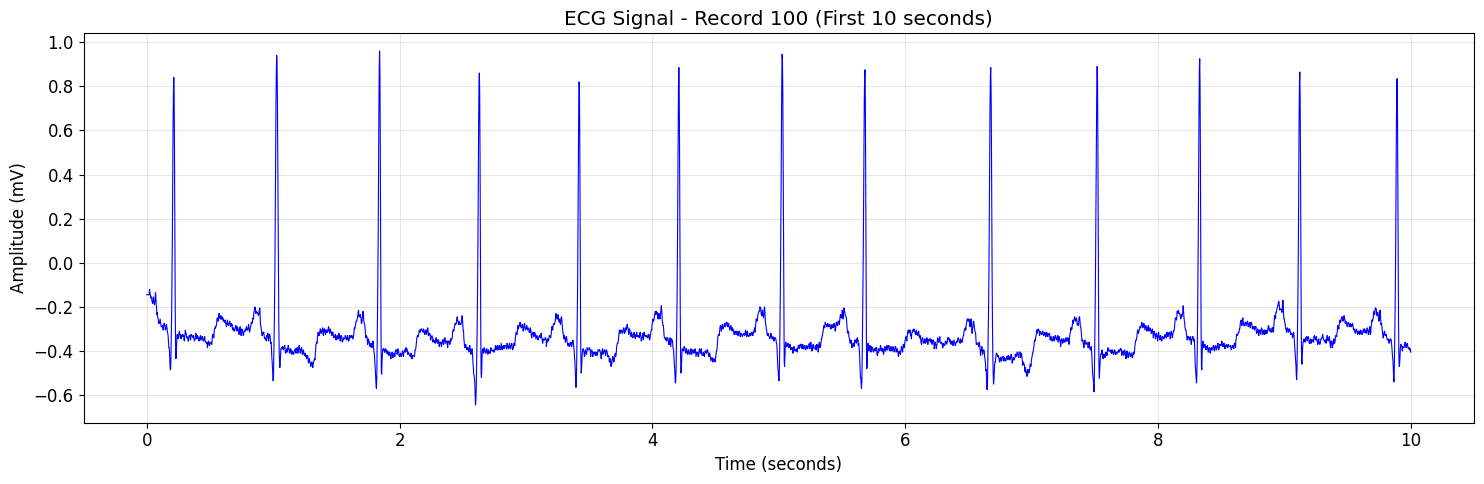

You should see regular, repeating patterns - these are heartbeats!
The large spikes are QRS complexes (ventricular contractions)


In [5]:
# Plot first 10 seconds of ECG
duration = 10  # seconds
samples = int(duration * record.fs)

time = np.arange(samples) / record.fs
ecg_signal = record.p_signal[:samples, 0]  # First channel

plt.figure(figsize=(15, 5))
plt.plot(time, ecg_signal, 'b-', linewidth=0.8)
plt.xlabel('Time (seconds)')
plt.ylabel('Amplitude (mV)')
plt.title('ECG Signal - Record 100 (First 10 seconds)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"You should see regular, repeating patterns - these are heartbeats!")
print(f"The large spikes are QRS complexes (ventricular contractions)")

## 3. Zooming in on a Single Heartbeat

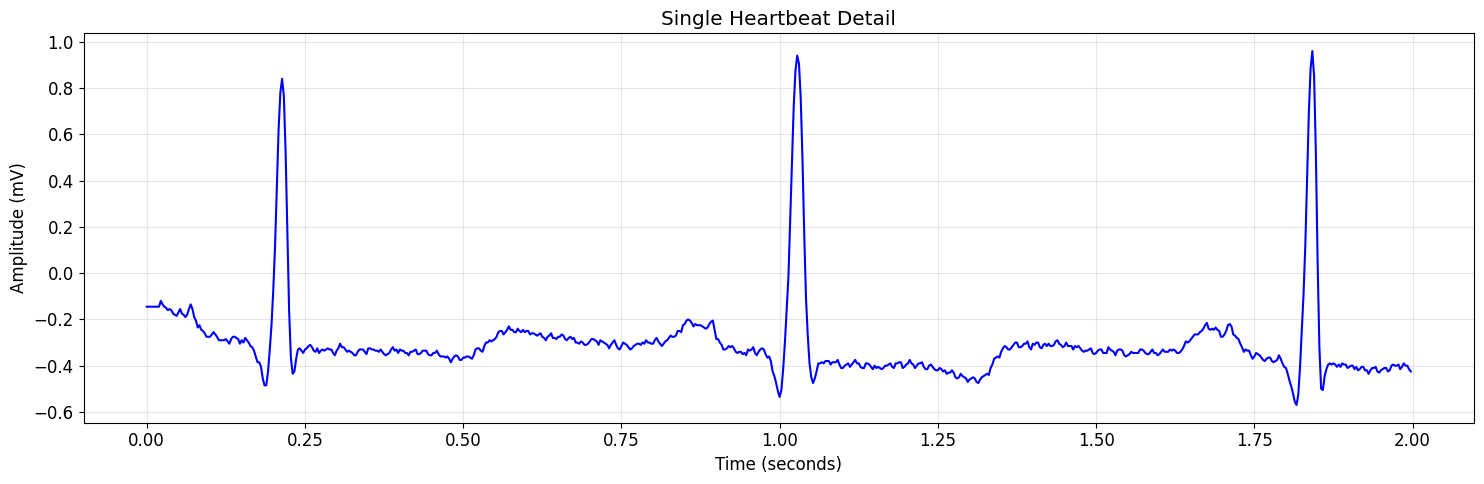

Now you can see the PQRST waves of individual heartbeats!


In [6]:
# Plot just 2 seconds to see individual beats clearly
duration = 2
samples = int(duration * record.fs)

time = np.arange(samples) / record.fs
ecg_signal = record.p_signal[:samples, 0]

plt.figure(figsize=(15, 5))
plt.plot(time, ecg_signal, 'b-', linewidth=1.5)
plt.xlabel('Time (seconds)')
plt.ylabel('Amplitude (mV)')
plt.title('Single Heartbeat Detail')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Now you can see the PQRST waves of individual heartbeats!")

## 4. Understanding Annotations

Each beat in the MIT-BIH database is labeled by cardiologists. Let's see what types of beats are in this recording.

In [7]:
from collections import Counter

# Count annotation types
symbol_counts = Counter(annotation.symbol)

print("Beat Type Distribution:")
print("-" * 50)
for symbol, count in symbol_counts.most_common():
    percentage = (count / len(annotation.symbol)) * 100
    print(f"{symbol}: {count:4d} beats ({percentage:5.1f}%)")

print("\nKey:")
print("N = Normal beat")
print("V = Premature ventricular contraction (PVC)")
print("A = Atrial premature beat")
print("And more...")

Beat Type Distribution:
--------------------------------------------------
N: 2239 beats ( 98.5%)
A:   33 beats (  1.5%)
+:    1 beats (  0.0%)
V:    1 beats (  0.0%)

Key:
N = Normal beat
V = Premature ventricular contraction (PVC)
A = Atrial premature beat
And more...


## 5. Comparing Normal vs Abnormal Beats

Let's visualize the difference between normal beats and arrhythmias.

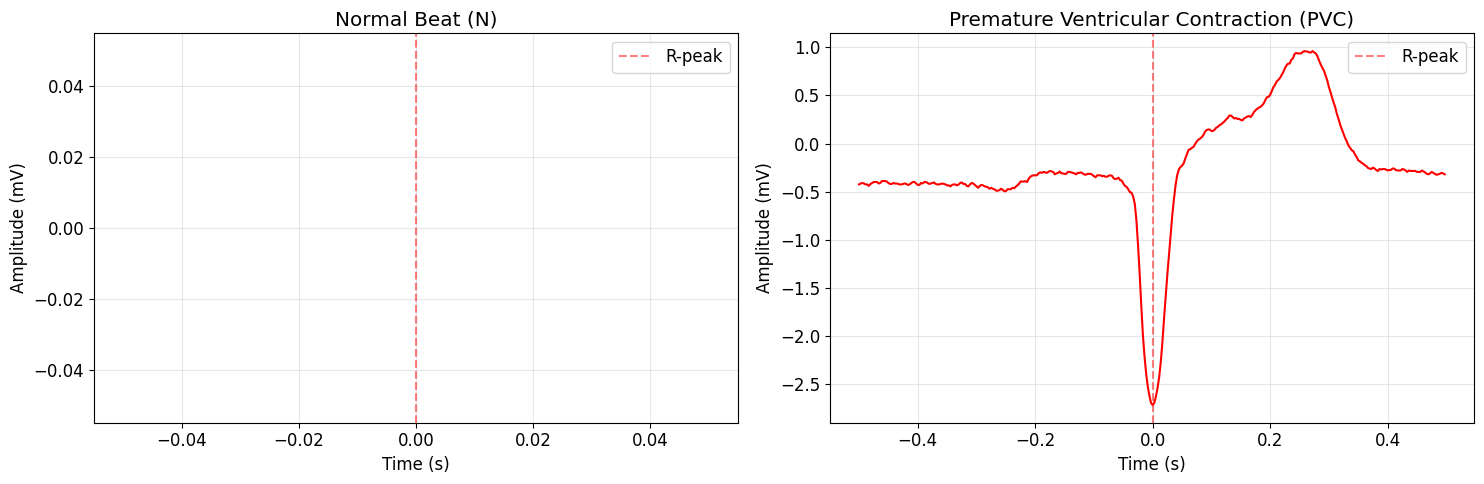

Notice the difference:
- Normal beat has typical PQRST morphology
- PVC has wider QRS complex and different shape


In [10]:
# Find first normal beat and first PVC (if exists)
normal_idx = None
pvc_idx = None

for i, symbol in enumerate(annotation.symbol):
    if symbol == 'N' and normal_idx is None:
        normal_idx = i
    if symbol == 'V' and pvc_idx is None:
        pvc_idx = i
    if normal_idx is not None and pvc_idx is not None:
        break

if normal_idx and pvc_idx:
    # Extract beat windows (0.5 seconds around each beat)
    window = int(0.5 * record.fs)
    
    normal_sample = annotation.sample[normal_idx]
    pvc_sample = annotation.sample[pvc_idx]
    
    normal_beat = record.p_signal[normal_sample-window:normal_sample+window, 0]
    pvc_beat = record.p_signal[pvc_sample-window:pvc_sample+window, 0]
    
    time_window = (np.arange(len(normal_beat)) - window) / record.fs
    pvc_time = (np.arange(len(pvc_beat)) - window) / record.fs
    
    # Plot comparison
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
    
    ax1.plot(time_window, normal_beat, 'b-', linewidth=1.5)
    ax1.set_title('Normal Beat (N)')
    ax1.set_xlabel('Time (s)')
    ax1.set_ylabel('Amplitude (mV)')
    ax1.grid(True, alpha=0.3)
    ax1.axvline(0, color='r', linestyle='--', alpha=0.5, label='R-peak')
    ax1.legend()
    
    ax2.plot(pvc_time, pvc_beat, 'r-', linewidth=1.5)
    ax2.set_title('Premature Ventricular Contraction (PVC)')
    ax2.set_xlabel('Time (s)')
    ax2.set_ylabel('Amplitude (mV)')
    ax2.grid(True, alpha=0.3)
    ax2.axvline(0, color='r', linestyle='--', alpha=0.5, label='R-peak')
    ax2.legend()
    
    plt.tight_layout()
    plt.show()
    
    print("Notice the difference:")
    print("- Normal beat has typical PQRST morphology")
    print("- PVC has wider QRS complex and different shape")
else:
    print("This record doesn't have PVCs. Try record 106 or 200 instead!")

## 6. Signal Quality and Noise

Real ECG signals have noise. Let's see what that looks like and why preprocessing is important.

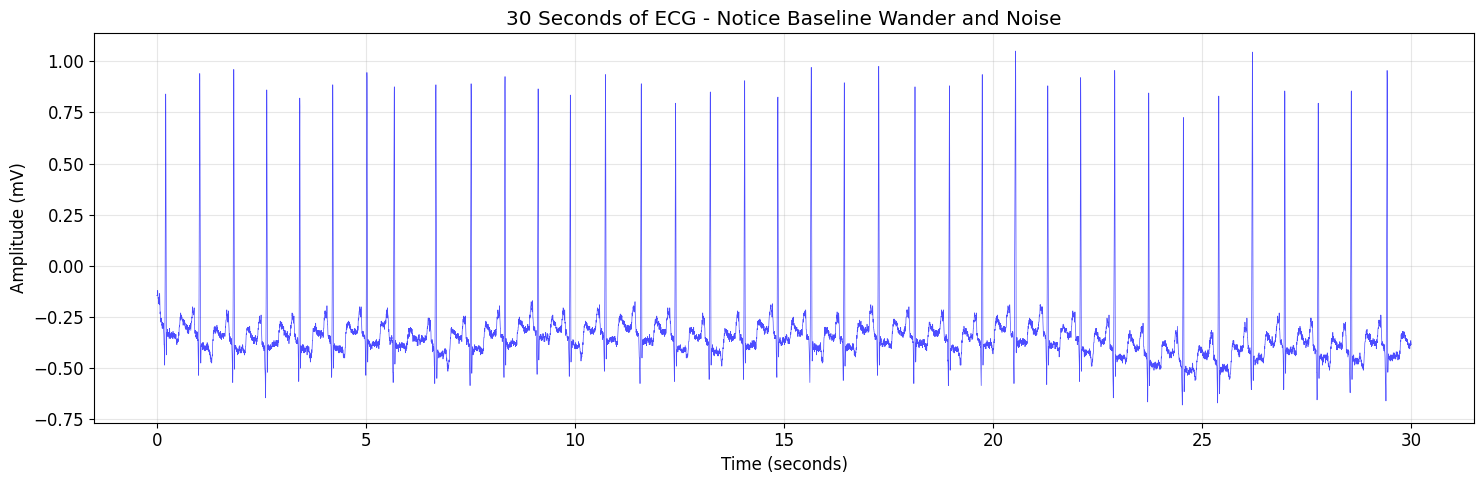

Challenges in real ECG signals:
1. Baseline wander (slow drift)
2. High-frequency noise
3. Motion artifacts
4. Power line interference (50/60 Hz)

This is why preprocessing is crucial!


In [11]:
# Plot a longer segment to see noise variation
duration = 30  # 30 seconds
samples = int(duration * record.fs)

time = np.arange(samples) / record.fs
ecg_signal = record.p_signal[:samples, 0]

plt.figure(figsize=(15, 5))
plt.plot(time, ecg_signal, 'b-', linewidth=0.5, alpha=0.7)
plt.xlabel('Time (seconds)')
plt.ylabel('Amplitude (mV)')
plt.title('30 Seconds of ECG - Notice Baseline Wander and Noise')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Challenges in real ECG signals:")
print("1. Baseline wander (slow drift)")
print("2. High-frequency noise")
print("3. Motion artifacts")
print("4. Power line interference (50/60 Hz)")
print("\nThis is why preprocessing is crucial!")

## 7. Basic Filtering Example

Let's apply a simple bandpass filter to clean the signal.

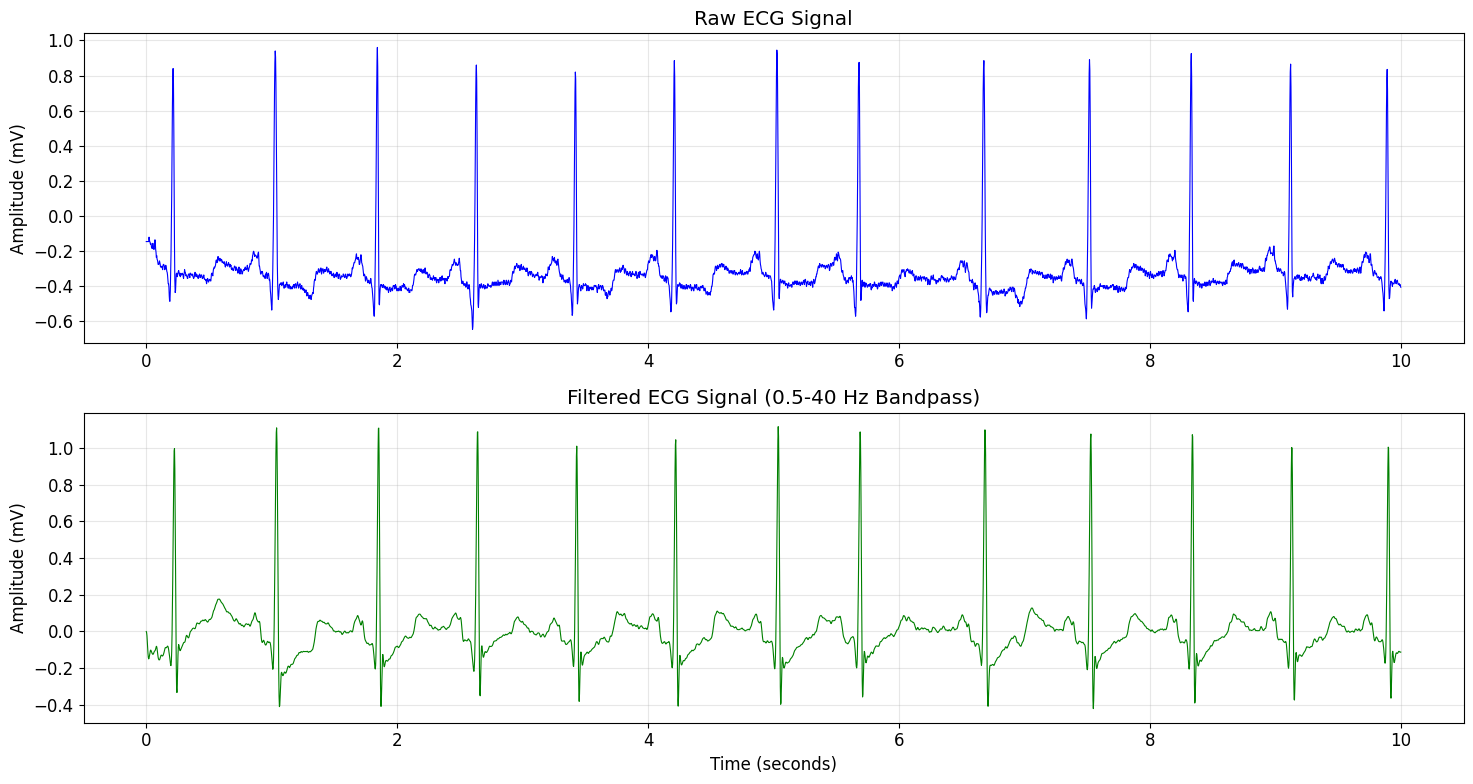

Filtered signal is cleaner and easier for ML models to process!


In [12]:
# Design bandpass filter (0.5-40 Hz is typical for ECG)
lowcut = 0.5
highcut = 40.0
fs = record.fs

# Create filter
sos = signal.butter(4, [lowcut, highcut], btype='band', fs=fs, output='sos')

# Apply filter
duration = 10
samples = int(duration * fs)
ecg_raw = record.p_signal[:samples, 0]
ecg_filtered = signal.sosfilt(sos, ecg_raw)

# Plot comparison
time = np.arange(samples) / fs

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 8))

ax1.plot(time, ecg_raw, 'b-', linewidth=0.8)
ax1.set_ylabel('Amplitude (mV)')
ax1.set_title('Raw ECG Signal')
ax1.grid(True, alpha=0.3)

ax2.plot(time, ecg_filtered, 'g-', linewidth=0.8)
ax2.set_xlabel('Time (seconds)')
ax2.set_ylabel('Amplitude (mV)')
ax2.set_title('Filtered ECG Signal (0.5-40 Hz Bandpass)')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("Filtered signal is cleaner and easier for ML models to process!")

## Summary and Next Steps

**What you learned:**
1. ✓ ECG signals show electrical activity of the heart
2. ✓ Normal beats have characteristic PQRST waves
3. ✓ Arrhythmias show different morphologies
4. ✓ Real signals have noise that needs filtering
5. ✓ MIT-BIH database has labeled data for training

**Next steps:**
1. Run `02_explore_data.py` to explore more records
2. Learn about different arrhythmia types
3. Start building preprocessing pipeline
4. Prepare data for model training

**Challenge:** Try loading different records (101, 106, 200, etc.) and see how they differ!

In [ ]:
# Your experiment space - try different records!
# Example: record = wfdb.rdrecord(os.path.join(DATA_DIR, '106'))
